## Abstract

A reusable, cloud-scalable pipeline that pairs Cellpose-SAM segmentation with on-demand GPU compute (Modal + S3) for single-cell phenotyping of high-content microscopy, demonstrated on a two-species yeast panel (*S. cerevisiae* vs. *S. pombe*).

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

High-content microscopy makes it easy to generate far more images than any single workstation can segment in a reasonable time. The bottleneck usually isn't the science — it's the plumbing: moving images, standing up GPUs, and getting consistent per-cell measurements out the other side. This pub shows one clean way to remove that bottleneck by combining a strong general-purpose segmentation model with elastic cloud GPU compute, so segmentation scales with your dataset instead of your hardware.

We pair Cellpose-SAM with on-demand GPU workers so the same segmentation code can run on one machine or across a full plate. On a two-species yeast panel, the per-cell shape measurements resolve *S. cerevisiae* from *S. pombe* — a check that the outputs are analysis-ready, not a claim about the organisms. This is not a Cellpose or Modal tutorial.

If you do high-throughput microscopy and want a segmentation and phenotyping pipeline, or you are deciding how to scale that compute without building the infrastructure yourself, the notebook is meant to be reused. Run it end-to-end on the example data, or take the same sequence — file I/O, segmentation, scale-out, per-cell measurements — and point it at your own images.

## How the pipeline fits together

:::{.callout-note title="Draft figure" collapse="false"}
A designed hero figure (in progress with Audrey) will replace the schematic below. The Mermaid diagram is a functional stand-in that captures the intended flow.
:::

The workflow is a straight line from raw images to per-cell measurements, with one key property: the segmentation step is identical whether it runs on one machine or hundreds of GPU containers. Scale is a deployment choice, not a code rewrite.

```{mermaid}
flowchart LR
  A["Brightfield ND2s<br/>datasets/&lt;id&gt;/raw/"] --> B["File I/O + preprocessing<br/>arcadia-microscopy-tools"]
  B --> C["Segmentation<br/>Cellpose-SAM → label masks"]
  C --> D{"Scale-out<br/>one worker per image"}
  D --> E["Derived artifacts<br/>masks · overlays · measurements"]
  E --> F["Analysis<br/>pooled per-cell morphology"]
  P["Plate map<br/>well → strain"] --> F
```

1. **Input:** brightfield ND2s in object storage, organized as `datasets/<id>/raw/`, with a plate map linking wells to strains.
2. **File I/O and preprocessing:** `arcadia-microscopy-tools` handles ND2 reading, channel and pixel-size metadata, and percentile rescaling.
3. **Segmentation:** Cellpose-SAM produces label masks; border-touching cells are dropped.
4. **Scale-out:** one worker per image is fanned across on-demand GPU containers, each reading from and writing to shared cloud storage.
5. **Outputs (`derived/`):** label-mask TIFFs, outline-overlay JPGs for QC, and per-cell measurement CSVs (regionprops, in microns where the pixel size is known).
6. **Analysis:** pooled per-cell measurements joined to the plate map for morphology comparisons across strains.

## A two-species yeast panel

The notebook runs on a small brightfield imaging dataset comprising two diploid yeast strains, eight wells each: *Saccharomyces cerevisiae* BY4743, an ovoid budding yeast, and *Schizosaccharomyces pombe* SP286, a rod-shaped fission yeast. Wells within each species are technical replicates.

| Species | Strain | Wells |
| --- | --- | --- |
| *S. cerevisiae* | `BY4743` | K01–K04, L01–L04 |
| *S. pombe* | `SP286` | K05–K08, L05–L08 |

The dataset is a small high-content, brightfield acquisition of the two yeasts above: 16 wells, four fields per well on a 2×2 grid, 64 ND2s in total. We used NIS-Elements JOBS to automate the plate-based acquisition.

`plate-map.csv` is the sample metadata. It maps each well to genus, species, strain, and ploidy. The NIS filenames already name the well and the field — `WellK01_PointK01_0000_Channelbrightfield_Seq0000.nd2` is the first point in well K01 — so joining on the well token attaches that metadata to every image, and later to every cell.

The ND2s also carry the instrument settings from acquisition (objective, pixel size, exposure, etc.). Those settings are the same for every file on the plate, so we only need to read one. The next cell copies a single ND2 from object storage and parses it with `arcadia-microscopy-tools`; the pipeline uses the same metadata to convert spatial measurements to microns.

The example images will be archived on Zenodo (record to be added). Internal readers with bucket access read the same files from S3.

In [1]:
# | code-fold: true
# | code-summary: "Code to load the example ND2 and extract metadata"

import subprocess
from pathlib import Path

import pandas as pd
from arcadia_microscopy_tools.nikon import parse_nd2

DATASET_ID = "20260611_141152_330"
EXAMPLE_ND2 = "WellK01_PointK01_0000_Channelbrightfield_Seq0000.nd2"
RAW_DIR = Path("scratch/sample_data") / DATASET_ID / "raw"
nd2_path = RAW_DIR / EXAMPLE_ND2

if not nd2_path.exists():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    src = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/raw/{EXAMPLE_ND2}"
    subprocess.run(["aws", "s3", "cp", src, f"{RAW_DIR}/"], check=True)

meta = parse_nd2(nd2_path)
cm = meta.channel_metadata_list[0]

pd.DataFrame.from_dict(
    {
        "file": nd2_path.name,
        "channel": cm.channel.name,
        "objective": cm.optics.objective,
        "magnification": cm.optics.magnification,
        "NA": cm.optics.numerical_aperture,
        "pixel_size_um": cm.resolution.xy_step_um,
        "exposure_s": cm.acquisition.exposure_time_s,
    },
    orient="index",
    columns=["value"],
)

,value
file,WellK01_PointK01_0000_Channelbrightfield_Seq00...
channel,BRIGHTFIELD
objective,PLAN APO λD 40x OFN25 DIC N2
magnification,40
NA,0.95
pixel_size_um,0.1625
exposure_s,0.01


## Demo: single-cell segmentation at scale

The code cells below run the full pipeline from start to finish. Cellpose-SAM [@pachitariu2025cellpose], implemented through `arcadia-microscopy-tools`, segments cells in the brightfield ND2 files and generates label masks, quality-control overlays, and per-cell measurement tables. The segmentation code runs in one of two interchangeable modes, chosen automatically so the notebook runs with or without connecting to our cloud infrastructure. All downstream cells run unchanged in either mode.

::: {.panel-tabset}

## Scaled execution (Modal + S3)

For Arcadia users with access to our cloud infrastructure, each ND2 file is processed by a separate GPU worker [@modal]. The worker reads the file from S3 and writes the resulting artifacts back to the bucket. This mode processes full plates efficiently by running files in parallel on GPUs.

## Local execution (no cloud account required)

TODO: is CPU truly default?
TODO: update Zenodo link

For external users, the same Cellpose-SAM code runs locally, using the CPU by default. Example ND2 files are downloaded from the public [Zenodo archive](https://zenodo.org/), and the `limit` parameter keeps the run short. This mode can also process full plates, but local (sequential) CPU execution is slower.

:::

The next code cell triggers the run. In either mode, `run_demo` processes $n=$`limit` images and returns the same result object, so the downstream cells remain unchanged. A progress bar advances as each image finishes and reports its cell count. Because the sorted file list begins with well K01, the three-image local sample contains only *S. cerevisiae*. Full-plate measurements and quality-control overlays are loaded separately below.

::: {.callout-note title="Forcing a backend" collapse="true"}
Set `CSCP_FORCE_LOCAL=1` to force the local path, or pass `backend="modal"` / `backend="local"` to `run_demo`. Details live in the [setup guide](pages/SETUP.qmd).
:::

In [12]:
# | code-fold: true
# | code-summary: "Code to trigger cell segmentation"

import time

from analysis.runner import run_demo

# Three images in both backends. Local CPU cannot do a full plate in a demo;
# files sort from well K01, so this sample is S. cerevisiae only.
# Full-plate measurements and QC overlays load separately below.
LIMIT = 3
CELL_DIAMETER = 60  # pixels
CELLPROP_THRESHOLD = 3.0

started = time.time()
run = run_demo(
    DATASET_ID,
    limit=LIMIT,
    diameter=CELL_DIAMETER,
    cellprob_threshold=CELLPROP_THRESHOLD,
)
elapsed = time.time() - started

if run.backend == "modal":
    print(f"[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/{run.output_prefix}/")
else:
    print(f"[local] Wrote artifacts to {run.output_prefix}")
print(f"Segmented {len(run.results)} image(s), {len(run.failures)} failure(s) in {elapsed:.1f}s.")

Segmenting: 100%|██████████| 3/3 [01:02<00:00, 20.95s/img, 2736 cells · 8657 total]


[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/datasets/20260611_141152_330/derived/
Segmented 3 image(s), 0 failure(s) in 69.5s.


## Visual QC: segmentation overlays

The pipeline generates a segmentation overlay for each image: cell boundaries (yellow) drawn on the brightfield. The figure below shows one field per species. Good segmentation traces each cell tightly without merging neighbors or splitting single cells. Border-touching cells are dropped, because truncation would bias their measurements.

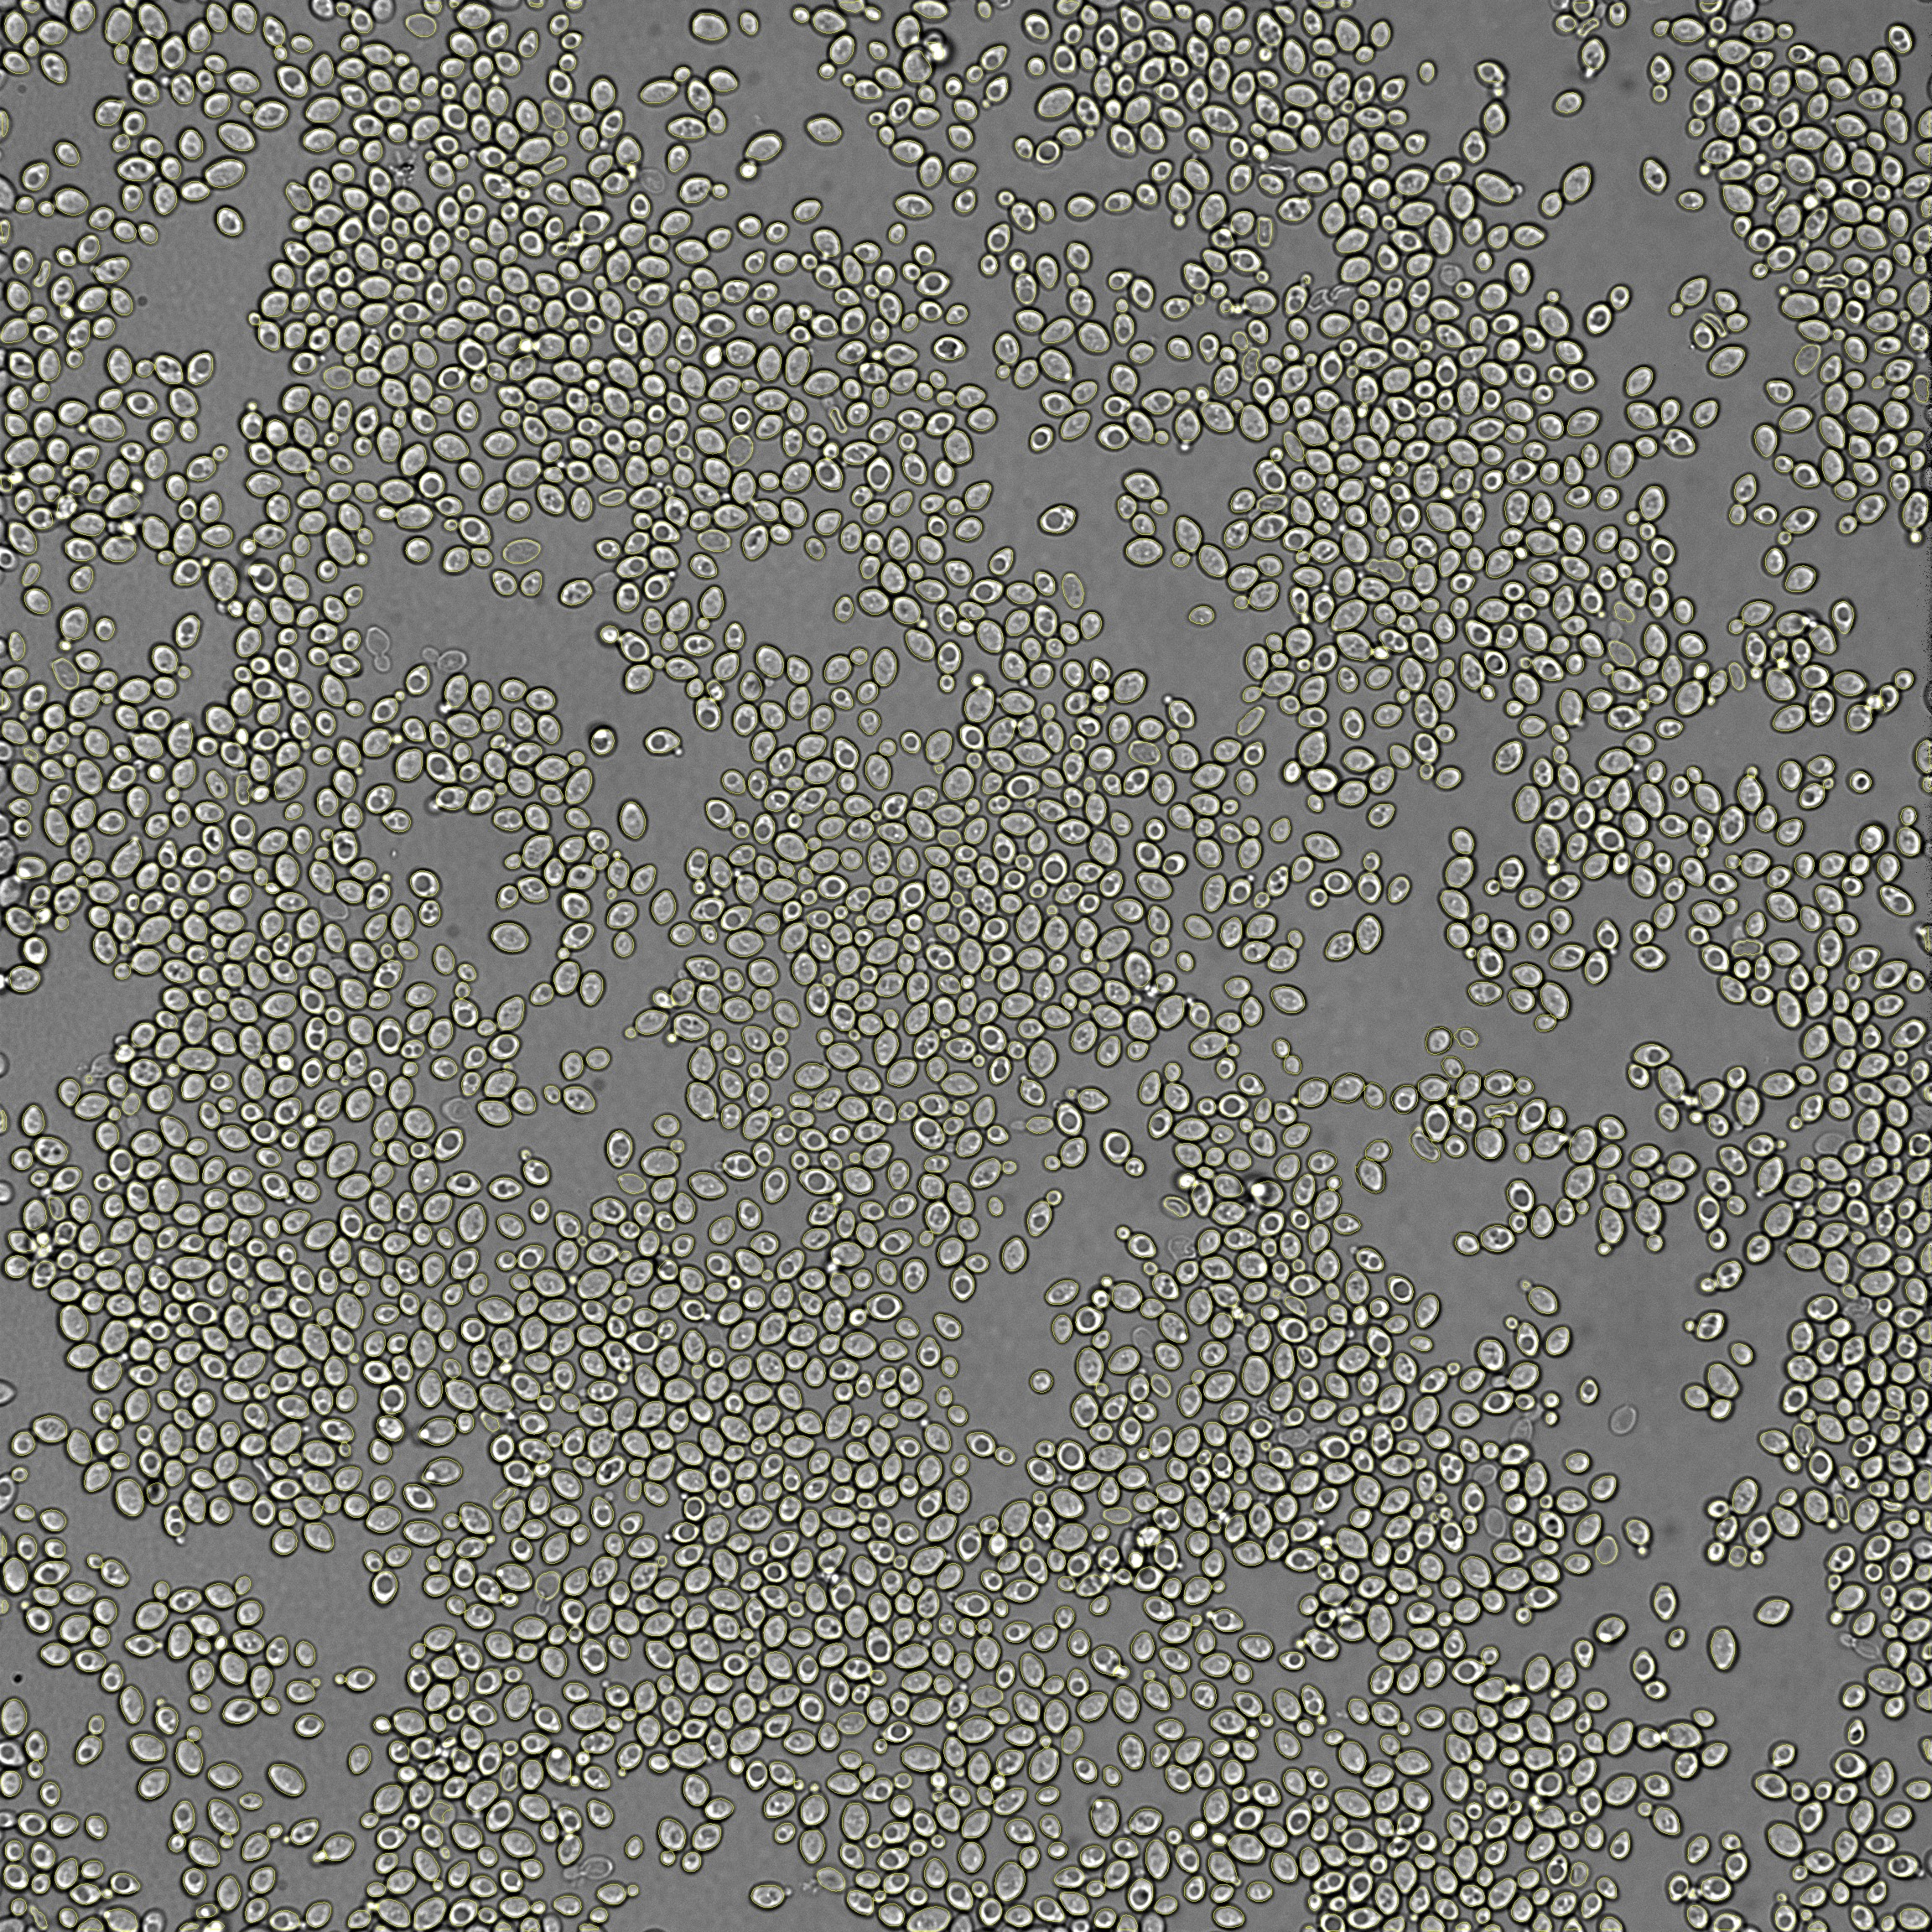

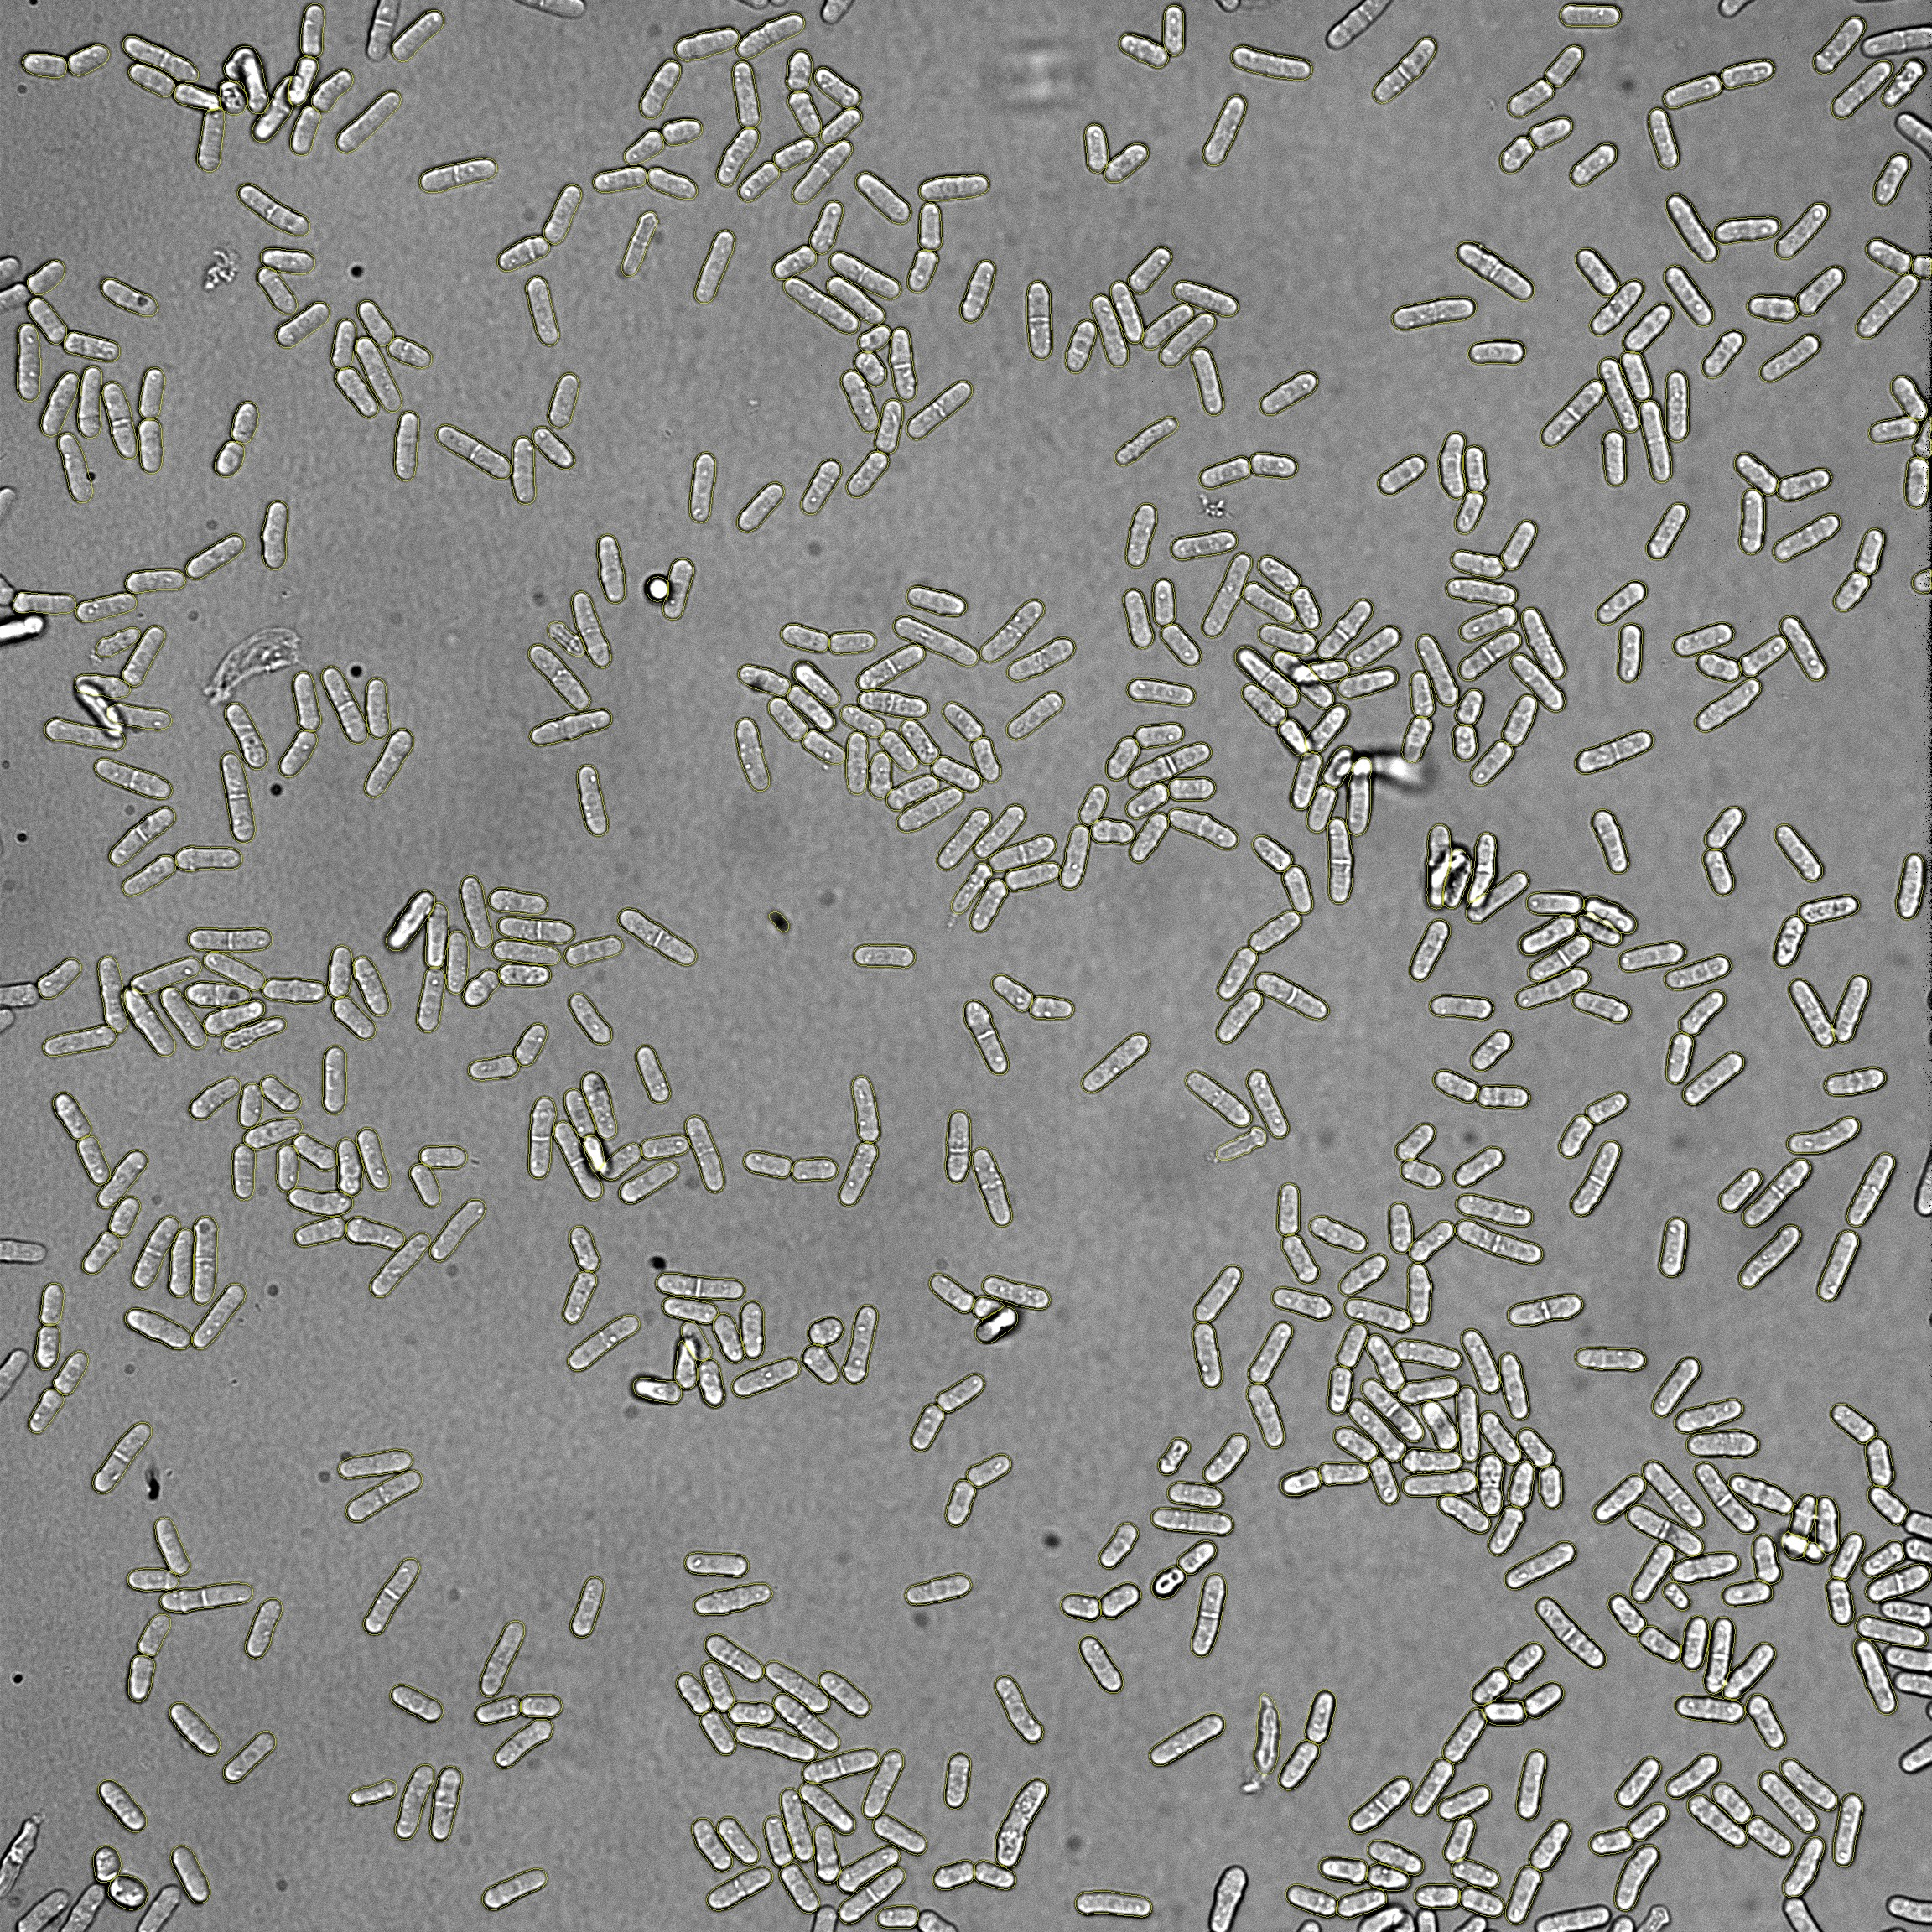

In [13]:
# | echo: false
# | label: fig-overlays
# | layout-ncol: 2
# | fig-cap: "Cellpose-SAM outlines on brightfield, one field per species."
# | fig-subcap:
# |   - "*S. cerevisiae* BY4743, well K01"
# |   - "*S. pombe* SP286, well K05"
# | fig-alt:
# |   - "Brightfield field of ovoid budding yeast with tight cell outlines."
# |   - "Brightfield field of rod-shaped fission yeast with tight cell outlines."

import re
import subprocess
from pathlib import Path

from IPython.display import Image as IPyImage
from IPython.display import display

QC_WELLS = ("K01", "K05")


def _well(name: str) -> str | None:
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


def _from_run(well: str) -> Path | None:
    for summary in run.results:
        path = summary.get("local_overlay")
        if not path:
            continue
        path = Path(path)
        name = str(summary.get("input", ""))
        if path.exists() and _well(name) == well:
            return path
    return None


def _from_derived(well: str) -> Path | None:
    dest_dir = Path("scratch/segmentation_results")
    dest_dir.mkdir(parents=True, exist_ok=True)
    for path in sorted(dest_dir.glob("*_overlay.jpg")):
        if _well(path.name) == well:
            return path
    prefix = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/derived/overlays/"
    try:
        listed = subprocess.run(
            ["aws", "s3", "ls", prefix], check=True, capture_output=True, text=True
        )
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None
    for line in listed.stdout.splitlines():
        name = line.split()[-1] if line.split() else ""
        if not (name.endswith("_overlay.jpg") and _well(name) == well):
            continue
        dest = dest_dir / name
        try:
            subprocess.run(
                ["aws", "s3", "cp", prefix + name, str(dest)],
                check=True,
                capture_output=True,
            )
        except (FileNotFoundError, subprocess.CalledProcessError):
            return None
        return dest if dest.exists() else None
    return None


for well in QC_WELLS:
    overlay = _from_run(well) or _from_derived(well)
    if overlay is None:
        raise FileNotFoundError(
            f"No overlay for well {well}. Run the demo cell above or copy "
            f"precomputed overlays from the dataset's derived/ prefix."
        )
    display(IPyImage(filename=str(overlay), width=480))

## Per-cell phenotyping outputs

The pipeline also produces per-cell measurements (regionprops, converted to microns where the pixel size is known): one row per cell, with shape features such as area, eccentricity, and axis lengths. We pool them across the segmented images and join each cell to its species via the plate map (well → species), so every cell carries a species label for the analysis that follows.

The segmentation workers also write these tables to `derived/<dataset>/measurements/` in shared storage, so you don't have to re-segment to analyze them. By default we use the measurements from the run above, but setting `MEASUREMENTS_SOURCE` in the next cell to `"auto"` loads the full precomputed table for **every** well — from the S3 bucket (internal readers) or the public Zenodo archive (external readers). That's the easiest way to get both species in the analysis when the local demo only segmented a few images.

In [5]:
import re
from pathlib import Path

import pandas as pd
from analysis.measurements import load_measurements

# Where the per-cell measurements come from:
#   "run"    - the table produced by the demo run above (only the images it
#              segmented; in local mode that is just LIMIT images from one species).
#   "auto"   - load the full precomputed table for the whole plate without
#              re-segmenting, from S3 (internal) or Zenodo (external). Use this to
#              analyze every well and both species.
#   "modal" / "zenodo" - force the S3 or Zenodo source explicitly.
MEASUREMENTS_SOURCE = "auto"

In [6]:
# | code-fold: true
# | code-summary: "Code to load per-cell measurements"

if MEASUREMENTS_SOURCE == "run":
    measurements = run.measurements.copy()
else:
    measurements = load_measurements(DATASET_ID, source=MEASUREMENTS_SOURCE)


def _find_plate_map() -> Path:
    for candidate in (Path("plate-map.csv"), Path("../plate-map.csv")):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("plate-map.csv not found next to the notebook or its parent.")


plate_map = pd.read_csv(_find_plate_map())


def well_from_name(name: str) -> str | None:
    """Pull a plate-well token (e.g. 'K01', 'WellL8') from an image name.

    DRAFT NOTE: confirm this matches the ND2 naming convention for your dataset.
    It normalizes to the plate-map form (uppercase row letter + zero-padded column).
    Rows span A-P so 384-well layouts (this dataset uses rows K/L) are covered.
    """
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


measurements["well"] = measurements["image"].map(well_from_name)
labeled = measurements.merge(plate_map[["well", "species", "strain"]], on="well", how="left")

n_unmapped = int(labeled["species"].isna().sum())
if n_unmapped:
    print(
        f"Warning: {n_unmapped} cell(s) had no species match; check well_from_name vs. your filenames."
    )
print(f"{len(labeled)} cells across {labeled['species'].nunique()} species.")
labeled.head()

113245 cells across 2 species.


,image,label,area_um2,area_convex_um2,perimeter_um,eccentricity,solidity,axis_major_length_um,axis_minor_length_um,orientation,...,volume_um3,centroid_y,centroid_x,intensity_mean_brightfield,intensity_max_brightfield,intensity_min_brightfield,intensity_std_brightfield,well,species,strain
0,WellK01_PointK01_0000_Channelbrightfield_Seq0000,1,26.010156,26.907969,19.211627,0.679895,0.966634,6.732396,4.936928,0.434690,...,85.917556,20.400000,258.336041,6814.699492,11560.0,2204.0,2128.836917,K01,cerevisiae,BY4743
1,WellK01_PointK01_0000_Channelbrightfield_Seq0000,2,9.242188,9.611875,11.230813,0.560397,0.961538,3.775817,3.127223,1.222603,...,19.334244,9.774286,409.551429,6956.957143,11136.0,2753.0,1826.916911,K01,cerevisiae,BY4743
2,WellK01_PointK01_0000_Channelbrightfield_Seq0000,3,8.344375,8.766875,10.810623,0.650373,0.951807,3.747865,2.846934,-0.375865,...,15.905132,11.496835,1908.161392,6312.629747,9258.0,2624.0,1620.173646,K01,cerevisiae,BY4743
3,WellK01_PointK01_0000_Channelbrightfield_Seq0000,4,16.134219,16.635938,14.789481,0.627140,0.969841,5.141493,4.004741,-0.088389,...,43.175435,15.538462,1928.641571,7316.826514,13169.0,3022.0,2192.698148,K01,cerevisiae,BY4743
4,WellK01_PointK01_0000_Channelbrightfield_Seq0000,5,34.777031,35.965313,22.798175,0.737879,0.966960,8.105407,5.470603,0.542464,...,127.011747,25.273349,181.623386,7317.725892,12398.0,2088.0,2058.817367,K01,cerevisiae,BY4743


## Shape alone separates the two species

The per-cell measurements are the pipeline's actual product, so the fair test of the pipeline is whether they support the kind of analysis you'd want to do next. We ask the simplest version of that question: given nothing but per-cell shape, can you tell the two yeasts apart? *S. cerevisiae* is an ovoid budding yeast and *S. pombe* is a rod, so the expected answer is yes — and that's the point. A pipeline that failed this test wouldn't be worth scaling. We're testing the measurements, not discovering biology.

Two steps follow. First we look at the joint distribution of the two features that should carry most of the signal, cell area and eccentricity. Then we rank every shape feature by how well it separates the species on its own.

Before any of that, we gate on cell area. Segmentation returns some objects that aren't single cells: fragments and debris at the small end, and clumps that Cellpose resolved as a single mask at the large end (the largest object in the full-plate table is about 1,270 µm², roughly fifty times the median *S. cerevisiae* cell). We keep objects between 5 and 100 µm², an area-equivalent circular diameter of 2.5–11.3 µm, which brackets a plausible single yeast cell. The gate is deliberately loose: it drops about 1% of objects and isn't tuned to flatter the analysis.

In [7]:
# | code-fold: true
# | code-summary: "Code to set up the analysis and gate on cell area"

import arcadia_pycolor as apc
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

apc.plotly.setup()

GROUP_COL = "species"
REFERENCE = "cerevisiae"  # the species the others are compared against
POSITIVE = "pombe"  # the "positive" class for AUC
AREA_COL = "area_um2" if "area_um2" in labeled.columns else "area"
AREA_LABEL = "cell area (µm²)" if AREA_COL == "area_um2" else "cell area (px)"

# Plausible-single-cell gate. 5-100 µm² is an area-equivalent circular diameter of
# 2.5-11.3 µm: below it, debris and partial masks; above it, merged clumps.
MIN_AREA_UM2 = 5.0
MAX_AREA_UM2 = 100.0

measured = labeled.dropna(subset=[GROUP_COL, AREA_COL])
# The gate is written in µm², so it only applies when the pixel size was known.
in_gate = (
    measured[AREA_COL].between(MIN_AREA_UM2, MAX_AREA_UM2)
    if AREA_COL == "area_um2"
    else pd.Series(True, index=measured.index)
)
analysis_df = measured.loc[in_gate].copy()

present = list(analysis_df[GROUP_COL].unique())
groups = ([REFERENCE] if REFERENCE in present else []) + sorted(
    g for g in present if g != REFERENCE
)

# Italicized "S. pombe"-style labels and a stable color per species, from the plate map.
genus_by_species = plate_map.drop_duplicates(GROUP_COL).set_index(GROUP_COL)["genus"]
DISPLAY = {species: f"<i>{genus_by_species[species][0]}. {species}</i>" for species in groups}
COLORS = dict(
    zip(groups, [apc.aegean.hex_code, apc.amber.hex_code, apc.seaweed.hex_code], strict=False)
)

n_dropped = int((~in_gate).sum())
print(
    f"{len(analysis_df):,} of {len(measured):,} cells pass the "
    f"{MIN_AREA_UM2:g}-{MAX_AREA_UM2:g} µm² gate "
    f"({n_dropped:,} dropped, {n_dropped / len(measured):.2%})."
)
print(
    f"{len(groups)} species across {analysis_df['well'].nunique()} well(s) and "
    f"{analysis_df['image'].nunique()} image(s): {', '.join(groups)}"
)

112,065 of 113,245 cells pass the 5-100 µm² gate (1,180 dropped, 1.04%).
2 species across 16 well(s) and 64 image(s): cerevisiae, pombe


In [8]:
# | code-fold: true
# | code-summary: "Code for the area-vs-eccentricity figure"

# Every cell is used for the marginal boxes; the scatter shows a random subsample per
# species, since 112,000 overplotted markers read as two solid blobs (and bloat the page).
POINTS_PER_SPECIES = 5000
rng = np.random.default_rng(0)


def box_stats(values):
    """Quartiles and Tukey fences for a Plotly box trace built from precomputed statistics."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    iqr = q3 - q1
    return dict(
        q1=[q1],
        median=[median],
        q3=[q3],
        lowerfence=[max(values.min(), q1 - 1.5 * iqr)],
        upperfence=[min(values.max(), q3 + 1.5 * iqr)],
        mean=[values.mean()],
    )


fig = make_subplots(
    rows=2,
    cols=2,
    column_widths=[0.85, 0.15],
    row_heights=[0.15, 0.85],
    shared_xaxes=True,
    shared_yaxes=True,
    horizontal_spacing=0.02,
    vertical_spacing=0.02,
)

for species in groups:
    cells = analysis_df[analysis_df[GROUP_COL] == species]
    color = COLORS[species]

    shown = cells.iloc[
        rng.choice(len(cells), size=min(POINTS_PER_SPECIES, len(cells)), replace=False)
    ]
    fig.add_trace(
        go.Scattergl(
            x=shown[AREA_COL],
            y=shown["eccentricity"],
            mode="markers",
            showlegend=False,
            marker=dict(color=color, size=3, opacity=0.4, line=dict(width=0)),
            hovertemplate=f"{species}<br>area %{{x:.1f}} µm²<br>ecc. %{{y:.2f}}<extra></extra>",
        ),
        row=2,
        col=1,
    )
    # A legend-only proxy, so the key shows a full-size, full-opacity marker.
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            name=f"{DISPLAY[species]}  (n = {len(cells):,})",
            marker=dict(color=color, size=9),
        ),
        row=2,
        col=1,
    )

    box_kwargs = dict(
        showlegend=False,
        fillcolor=color,
        line=dict(color=apc.charcoal.hex_code, width=1),
        width=0.45,
        hoverinfo="skip",
    )
    fig.add_trace(
        go.Box(**box_stats(cells[AREA_COL].to_numpy()), y=[species], orientation="h", **box_kwargs),
        row=1,
        col=1,
    )
    fig.add_trace(
        go.Box(**box_stats(cells["eccentricity"].to_numpy()), x=[species], **box_kwargs),
        row=2,
        col=2,
    )

fig.update_xaxes(title_text=AREA_LABEL, range=[0, MAX_AREA_UM2], row=2, col=1)
fig.update_yaxes(title_text="eccentricity", range=[0, 1.02], row=2, col=1)
for row, col in ((1, 1), (2, 2)):  # the marginals borrow their scale from the scatter
    fig.update_xaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)
    fig.update_yaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)

fig.update_layout(
    width=720,
    height=560,
    title="Area and eccentricity split the panel into two populations",
    legend=dict(
        x=0.99, y=0.03, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.75)"
    ),
)
apc.plotly.style_plot(fig, monospaced_axes="xy", row=2, col=1)
fig.show()

The two clouds barely touch. *S. pombe* traces a tight arc, which is what fission yeast morphology predicts: it grows by extending its tips at roughly constant width, so a cell gets larger and more elongated at the same time, and area and eccentricity rise together over the cell cycle. *S. cerevisiae* instead fills a broad, rounder cloud with a tail toward small area and low eccentricity — mostly small buds. The marginal boxes show where the separation actually comes from: the area distributions overlap substantially, since a large budding yeast is the size of a small fission yeast, while the eccentricity distributions hardly overlap at all.

### Ranking every shape feature

Area and eccentricity are two of the nine shape features the pipeline reports. To rank all of them, we use the area under the ROC curve for each feature on its own — the probability that a randomly chosen *S. pombe* cell scores higher than a randomly chosen *S. cerevisiae* cell. An AUC of 0.5 means the feature is useless and 1.0 means the two distributions don't overlap at all. It's a rank statistic, so the long tails in these distributions don't distort it.

We also report a Mann–Whitney p-value on the well-level medians, not on the individual cells. Cells from the same well share a field of view, a focus plane, and an illumination profile, so a test across all 100,000+ cells would treat those shared conditions as independent observations and return p ≈ 0 for every feature. The table instead compares sixteen well medians, eight per species. With eight versus eight, the smallest two-sided p-value is 1.6 × 10⁻⁴, and several features reach it because their well medians do not overlap. Those wells are technical replicates, so the test measures consistency across wells rather than a difference between the species.

In [9]:
# | code-fold: true
# | code-summary: "Code to rank shape features by how well each one separates the species"

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

# Shape only. Orientation is an arbitrary lab-frame angle, the centroids are positions, and
# the brightfield intensities describe illumination as much as they describe the cell.
FEATURES = {
    "area_um2": "area (µm²)",
    "area_convex_um2": "convex area (µm²)",
    "perimeter_um": "perimeter (µm)",
    "axis_major_length_um": "major axis (µm)",
    "axis_minor_length_um": "minor axis (µm)",
    "eccentricity": "eccentricity",
    "solidity": "solidity",
    "circularity": "circularity",
    "volume_um3": "volume (µm³)",
}
FEATURES = {col: label for col, label in FEATURES.items() if col in analysis_df.columns}

is_positive = (analysis_df[GROUP_COL] == POSITIVE).to_numpy()
well_medians = analysis_df.groupby(["well", GROUP_COL])[list(FEATURES)].median().reset_index()

rows = []
for col, label in FEATURES.items():
    auc = roc_auc_score(is_positive, analysis_df[col])
    _, p_well = mannwhitneyu(
        well_medians.loc[well_medians[GROUP_COL] == POSITIVE, col],
        well_medians.loc[well_medians[GROUP_COL] == REFERENCE, col],
        alternative="two-sided",
    )
    rows.append(
        {
            "feature": label,
            f"median, {REFERENCE}": round(analysis_df.loc[~is_positive, col].median(), 2),
            f"median, {POSITIVE}": round(analysis_df.loc[is_positive, col].median(), 2),
            # Flip AUCs below 0.5 so every feature is scored in its discriminating direction.
            "AUC": round(max(auc, 1 - auc), 3),
            "well-level p": f"{p_well:.1e}",
        }
    )

feature_stats = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
feature_stats

,feature,"median, cerevisiae","median, pombe",AUC,well-level p
0,eccentricity,0.60,0.92,0.995,1.6e-04
1,circularity,0.89,0.67,0.991,1.6e-04
2,major axis (µm),6.31,12.34,0.990,1.6e-04
3,perimeter (µm),18.62,29.00,0.976,9.2e-04
4,convex area (µm²),25.30,46.79,0.952,9.3e-04
5,area (µm²),24.48,45.02,0.951,9.3e-04
6,volume (µm³),81.18,144.19,0.876,1.6e-04
7,solidity,0.97,0.96,0.624,1.6e-04
8,minor axis (µm),4.94,4.73,0.585,1.6e-04


Eccentricity leads at an AUC of 0.995, with circularity and major-axis length close behind: all three are measuring elongation. The size features land lower (area at 0.951), and the two features that describe neither elongation nor size, solidity and minor-axis length, are barely better than a coin flip. That last result is the one worth noting: fission yeast and budding yeast are about the same width, so a feature that only knew cell width would have almost nothing to work with.

## What this demo does not show

- **Scope:** gross morphology only, from single-channel brightfield images. Staining- or fluorescence-based phenotyping is a natural extension, not shown here.
- **Compute and cost:** the scaled path relies on paid GPU compute and cloud storage. The local CPU fallback is scoped to a few images so anyone can reproduce the core result without an account, but it does not exercise the scale-out.
- **Replication:** a single dataset with multiple wells per species (technical, not biological, replicates). Enough to show the pipeline produces stable, species-resolved phenotypes; not enough to make claims about the organisms.

## Acknowledgements

Overview-figure design by Audrey. Contributors and author list to be added.

The pipeline combines [`arcadia-microscopy-tools`](https://github.com/Arcadia-Science/arcadia-microscopy-tools) for file I/O, preprocessing, and measurements [@amt]; Cellpose-SAM for segmentation [@pachitariu2025cellpose]; and [Modal](https://modal.com/) for on-demand GPU compute [@modal], with artifacts stored on Amazon S3.

::: {.callout-note title="Run it yourself"}
Environment setup and both backends (Modal + S3, or local CPU on the Zenodo sample) live in the [setup guide](pages/SETUP.qmd).
:::

## Appendix {#sec-appendix}

`SegmentConfig` knobs forwarded to Cellpose-SAM, plus the Modal scale-out parameters. Defaults match a typical brightfield yeast field; change them in `run_demo(...)` if your cells differ.

| Parameter | Default | Role |
| --- | --- | --- |
| `diameter` | `None` (30 px) | Expected cell diameter in pixels |
| `flow_threshold` | `0.4` | Mask quality filter (higher is stricter) |
| `cellprob_threshold` | `0.0` | Cell-probability cutoff (higher yields fewer, more confident masks) |
| `percentile_low` / `percentile_high` | `1.0` / `99.0` | Contrast-stretch window before segmentation |
| `gpu` | `L4` | Modal GPU type |
| `max_containers` | `10` | Ceiling on concurrent GPU workers |

: Segmentation and scale-out parameters {#tbl-segment-config}